In [1]:
from google.colab import files

uploaded = files.upload()

Saving hillstrom.csv to hillstrom (2).csv


In [2]:
import pandas as pd

file_name = next(iter(uploaded))
df = pd.read_csv(file_name)

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

df.head()

Rows: 64000
Columns: 12


,recency,history_segment,history,mens,womens,zip_code,newbie,channel,segment,visit,conversion,spend
0,10,2) $100 - $200,142.44,1,0,Surburban,0,Phone,Womens E-Mail,0,0,0.0
1,6,3) $200 - $350,329.08,1,1,Rural,1,Web,No E-Mail,0,0,0.0
2,7,2) $100 - $200,180.65,0,1,Surburban,1,Web,Womens E-Mail,0,0,0.0
3,9,5) $500 - $750,675.83,1,0,Rural,1,Web,Mens E-Mail,0,0,0.0
4,2,1) $0 - $100,45.34,1,0,Urban,0,Web,Womens E-Mail,0,0,0.0


In [3]:
df["segment"].value_counts()

,count
segment,
Womens E-Mail,21387
Mens E-Mail,21307
No E-Mail,21306


In [4]:
df.isna().sum()

,0
recency,0
history_segment,0
history,0
mens,0
womens,0
zip_code,0
newbie,0
channel,0
segment,0
visit,0


In [5]:
df.dtypes

,0
recency,int64
history_segment,object
history,float64
mens,int64
womens,int64
zip_code,object
newbie,int64
channel,object
segment,object
visit,int64


In [6]:
binary_columns = ["mens", "womens", "newbie", "visit", "conversion"]

for column in binary_columns:
    print(column, sorted(df[column].unique()))

mens [np.int64(0), np.int64(1)]
womens [np.int64(0), np.int64(1)]
newbie [np.int64(0), np.int64(1)]
visit [np.int64(0), np.int64(1)]
conversion [np.int64(0), np.int64(1)]


In [7]:
df[["recency", "history", "spend"]].describe().round(2)

,recency,history,spend
count,64000.00,64000.00,64000.00
mean,5.76,242.09,1.05
std,3.51,256.16,15.04
min,1.00,29.99,0.00
25%,2.00,64.66,0.00
50%,6.00,158.11,0.00
75%,9.00,325.66,0.00
max,12.00,3345.93,499.00


In [8]:
buyers = df["conversion"] == 1
positive_spend = df["spend"] > 0

print("Purchasers:", buyers.sum())
print("Purchase rate:", f"{buyers.mean():.2%}")
print("Customers with positive spending:", positive_spend.sum())
print("Purchase/spending mismatches:", (buyers != positive_spend).sum())

Purchasers: 578
Purchase rate: 0.90%
Customers with positive spending: 578
Purchase/spending mismatches: 0


Initial data checks

The dataset contains 64,000 customers across three campaign-assignment groups of approximately equal size. No missing values were detected, and all binary indicators contain only 0 and 1.

There are 578 purchasers (0.90% of customers). Purchase indicators agree with positive spending for every record. Post-campaign spending is highly concentrated: most customers spend nothing, while a small number make purchases.

All customers, including nonpurchasers, will be retained when estimating revenue per customer. The limited number of purchases will be considered when interpreting subgroup estimates and targeting comparisons.

In [9]:
baseline_columns = ["recency", "history", "mens", "womens", "newbie"]

baseline_means = df.groupby("segment")[baseline_columns].mean()

baseline_means.round(3)


,recency,history,mens,womens,newbie
segment,,,,,
Mens E-Mail,5.774,242.836,0.551,0.551,0.502
No E-Mail,5.750,240.883,0.553,0.548,0.502
Womens E-Mail,5.768,242.537,0.549,0.550,0.503


In [10]:
for column in ["channel", "zip_code"]:
    print(f"\n{column}: percentage within each experimental group")
    display(
        pd.crosstab(
            df["segment"], df[column], normalize="index"
        ).mul(100).round(1)
    )


channel: percentage within each experimental group


channel,Multichannel,Phone,Web
segment,,,
Mens E-Mail,12.1,43.4,44.5
No E-Mail,12.2,43.8,44.0
Womens E-Mail,12.1,44.2,43.7



zip_code: percentage within each experimental group


zip_code,Rural,Surburban,Urban
segment,,,
Mens E-Mail,15.2,44.6,40.2
No E-Mail,14.7,45.2,40.1
Womens E-Mail,14.9,45.1,40.0


**Analysis plan — recorded after preliminary data checks**

**Research question:** At the same contact rate, does targeting customers by estimated incremental revenue outperform targeting by historical spending or predicted purchasing behavior?

**Primary comparison:** Men’s merchandise email versus no email. The women’s merchandise email will provide a secondary comparison.

**Outcomes:** Revenue per customer, including zero spending, is the primary outcome. Purchase probability is secondary.

**Analysis sequence:** First estimate the average campaign effects and their uncertainty. Then compare random targeting, historical-spending targeting, purchase-probability targeting, predicted-revenue targeting, and incremental-revenue targeting.

**Contact rates:** The primary comparison will contact 25% of customers; 10% and 50% will be secondary comparisons.

**Evaluation:** Separate training, validation, and final test samples. Final test outcomes will not be used to select models or targeting rules.

**Interpretation:** Report uncertainty and inconclusive results. Treat this study as an independent replication and extension using public experimental data.


In [11]:
from sklearn.model_selection import train_test_split

# Select the two groups for our primary comparison.
main_df = df[
    df["segment"].isin(["Mens E-Mail", "No E-Mail"])
].copy()

# 1 means assigned the email; 0 means assigned no email.
main_df["treatment"] = (
    main_df["segment"] == "Mens E-Mail"
).astype(int)

# Reserve 40% for validation and final testing.
train_df, remaining_df = train_test_split(
    main_df,
    test_size=0.40,
    stratify=main_df["treatment"],
    random_state=42
)

# Divide that reserved sample equally.
validation_df, test_df = train_test_split(
    remaining_df,
    test_size=0.50,
    stratify=remaining_df["treatment"],
    random_state=42
)

print("Primary sample:", len(main_df))
print("Training:", len(train_df))
print("Validation:", len(validation_df))
print("Final test:", len(test_df))

Primary sample: 42613
Training: 25567
Validation: 8523
Final test: 8523


In [12]:
training_summary = train_df.groupby("segment").agg(
    customers=("conversion", "size"),
    purchasers=("conversion", "sum"),
    purchase_rate_pct=("conversion", "mean"),
    revenue_per_customer=("spend", "mean")
)

training_summary["purchase_rate_pct"] *= 100

training_summary.round(3)

,customers,purchasers,purchase_rate_pct,revenue_per_customer
segment,,,,
Mens E-Mail,12784,155,1.212,1.354
No E-Mail,12783,70,0.548,0.684


In [13]:
from scipy import stats

email_revenue = train_df.loc[
    train_df["treatment"] == 1, "spend"
]

control_revenue = train_df.loc[
    train_df["treatment"] == 0, "spend"
]

revenue_difference = email_revenue.mean() - control_revenue.mean()

revenue_test = stats.ttest_ind(
    email_revenue,
    control_revenue,
    equal_var=False
)

revenue_ci = revenue_test.confidence_interval(
    confidence_level=0.95
)

print(f"Revenue difference per customer: ${revenue_difference:.3f}")
print(f"95% confidence interval: (${revenue_ci.low:.3f}, ${revenue_ci.high:.3f})")

Revenue difference per customer: $0.670
95% confidence interval: ($0.305, $1.034)


In [14]:
email_purchase = train_df.loc[
    train_df["treatment"] == 1, "conversion"
]

control_purchase = train_df.loc[
    train_df["treatment"] == 0, "conversion"
]

purchase_difference = 100 * (
    email_purchase.mean() - control_purchase.mean()
)

purchase_ci = stats.ttest_ind(
    email_purchase,
    control_purchase,
    equal_var=False
).confidence_interval(confidence_level=0.95)

print(
    f"Purchase-rate difference: "
    f"{purchase_difference:.3f} percentage points"
)

print(
    f"95% confidence interval: "
    f"({100 * purchase_ci.low:.3f}, "
    f"{100 * purchase_ci.high:.3f}) percentage points"
)

Purchase-rate difference: 0.665 percentage points
95% confidence interval: (0.436, 0.894) percentage points


**Average campaign effects — training sample**

The analysis compares 12,784 customers assigned to the men’s merchandise email with 12,783 assigned to no email.

Email assignment increased estimated revenue per customer by **\$0.670**, wit
h an approximate 95% confidence interval of **\$0.305 to \$1.034**. This calculation includes customers who spent nothing.

The estimated increase in purchase probability was **0.665 percentage points**, with an approximate 95% confidence interval of **0.436 to 0.894 percentage points**.

Both intervals exclude zero, providing evidence of positive average campaign effects. These results do not establish which customers benefit most from receiving the email or whether model-based targeting improves revenue. Profitability also depends on costs that are not provided in the dataset.

Validation and final test outcomes remain unused.

In [15]:
numeric_features = [
    "recency",
    "history",
    "mens",
    "womens",
    "newbie"
]

categorical_features = ["channel", "zip_code"]

feature_columns = numeric_features + categorical_features

X_train = train_df[feature_columns].copy()

print("Training rows and input columns:", X_train.shape)
print("Model inputs:", feature_columns)

Training rows and input columns: (25567, 7)
Model inputs: ['recency', 'history', 'mens', 'womens', 'newbie', 'channel', 'zip_code']


In [16]:
contact_rate = 0.25
n_to_contact = int(contact_rate * len(validation_df))

# Identify customers with the highest historical spending.
selected_indices = validation_df["history"].nlargest(
    n_to_contact, keep="first"
).index

# True = selected for contact; False = not selected.
history_policy_valid = pd.Series(
    False, index=validation_df.index
)

history_policy_valid.loc[selected_indices] = True

print("Validation customers:", len(validation_df))
print("Selected for contact:", history_policy_valid.sum())
print("Contact rate:", f"{history_policy_valid.mean():.2%}")


Validation customers: 8523
Selected for contact: 2130
Contact rate: 24.99%


In [17]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

preprocessor = ColumnTransformer([
    ("numeric", StandardScaler(), numeric_features),
    ("categorical", OneHotEncoder(handle_unknown="ignore"),
     categorical_features)
])

purchase_model = Pipeline([
    ("preprocess", preprocessor),
    ("model", LogisticRegression(max_iter=2000))
])

emailed_train = train_df.loc[
    train_df["treatment"] == 1
].copy()

purchase_model.fit(
    emailed_train[feature_columns],
    emailed_train["conversion"]
)

print("Purchase model trained.")
print("Training customers used:", len(emailed_train))

Purchase model trained.
Training customers used: 12784


In [18]:
purchase_probability_valid = pd.Series(
    purchase_model.predict_proba(
        validation_df[feature_columns]
    )[:, 1],
    index=validation_df.index
)

selected_indices = purchase_probability_valid.nlargest(
    n_to_contact, keep="first"
).index

purchase_policy_valid = pd.Series(
    False, index=validation_df.index
)
purchase_policy_valid.loc[selected_indices] = True

overlap = (purchase_policy_valid & history_policy_valid).sum()

print("Selected for contact:", purchase_policy_valid.sum())
print("Contact rate:", f"{purchase_policy_valid.mean():.2%}")
print("Also selected by historical-spending rule:", overlap)

Selected for contact: 2130
Contact rate: 24.99%
Also selected by historical-spending rule: 1336


In [19]:
from sklearn.metrics import roc_auc_score, log_loss

emailed_valid = validation_df["treatment"] == 1

y_valid = validation_df.loc[emailed_valid, "conversion"]
p_valid = purchase_probability_valid.loc[emailed_valid]

# Benchmark: predict the training purchase rate for everyone.
baseline_predictions = pd.Series(
    emailed_train["conversion"].mean(),
    index=y_valid.index
)

prediction_check = pd.DataFrame({
    "Logistic regression": {
        "ROC AUC": roc_auc_score(y_valid, p_valid),
        "Log loss": log_loss(y_valid, p_valid)
    },
    "Constant baseline": {
        "ROC AUC": roc_auc_score(y_valid, baseline_predictions),
        "Log loss": log_loss(y_valid, baseline_predictions)
    }
})

prediction_check.round(4)

,Logistic regression,Constant baseline
ROC AUC,0.5853,0.5000
Log loss,0.0751,0.0752


In [20]:
from sklearn.base import clone
from sklearn.linear_model import Ridge

revenue_model = Pipeline([
    ("preprocess", clone(preprocessor)),
    ("model", Ridge(alpha=1.0))
])

revenue_model.fit(
    emailed_train[feature_columns],
    emailed_train["spend"]
)

print("Revenue model trained.")
print("Training customers used:", len(emailed_train))

Revenue model trained.
Training customers used: 12784


In [21]:
predicted_revenue_valid = pd.Series(
    revenue_model.predict(validation_df[feature_columns]),
    index=validation_df.index
)

selected_indices = predicted_revenue_valid.nlargest(
    n_to_contact, keep="first"
).index

revenue_policy_valid = pd.Series(
    False, index=validation_df.index
)
revenue_policy_valid.loc[selected_indices] = True

print("Selected for contact:", revenue_policy_valid.sum())
print("Contact rate:", f"{revenue_policy_valid.mean():.2%}")
print(
    "Also selected by purchase-probability rule:",
    (revenue_policy_valid & purchase_policy_valid).sum()
)
print(
    "Negative revenue predictions:",
    (predicted_revenue_valid < 0).sum()
)

Selected for contact: 2130
Contact rate: 24.99%
Also selected by purchase-probability rule: 1807
Negative revenue predictions: 0


In [22]:
from sklearn.metrics import mean_squared_error

y_revenue_valid = validation_df.loc[emailed_valid, "spend"]
p_revenue_valid = predicted_revenue_valid.loc[emailed_valid]

baseline_revenue_valid = pd.Series(
    emailed_train["spend"].mean(),
    index=y_revenue_valid.index
)

revenue_prediction_check = pd.DataFrame({
    "RMSE": [
        mean_squared_error(
            y_revenue_valid, p_revenue_valid
        ) ** 0.5,
        mean_squared_error(
            y_revenue_valid, baseline_revenue_valid
        ) ** 0.5
    ],
    "Mean predicted spending": [
        p_revenue_valid.mean(),
        baseline_revenue_valid.mean()
    ]
}, index=["Ridge regression", "Constant baseline"])

display(revenue_prediction_check.round(4))

print(
    "Observed mean spending:",
    round(y_revenue_valid.mean(), 4)
)

,RMSE,Mean predicted spending
Ridge regression,22.1789,1.3651
Constant baseline,22.1586,1.3536


Observed mean spending: 1.8565


In [23]:
control_train = train_df.loc[
    train_df["treatment"] == 0
].copy()

# Create a fresh, unfitted copy of the revenue pipeline.
control_revenue_model = clone(revenue_model)

control_revenue_model.fit(
    control_train[feature_columns],
    control_train["spend"]
)

print("Control revenue model trained.")
print("Training customers used:", len(control_train))

Control revenue model trained.
Training customers used: 12783


In [24]:
predicted_control_revenue_valid = pd.Series(
    control_revenue_model.predict(
        validation_df[feature_columns]
    ),
    index=validation_df.index
)

incremental_revenue_valid = (
    predicted_revenue_valid - predicted_control_revenue_valid
)

selected_indices = incremental_revenue_valid.nlargest(
    n_to_contact, keep="first"
).index

incremental_policy_valid = pd.Series(
    False, index=validation_df.index
)
incremental_policy_valid.loc[selected_indices] = True

print("Selected for contact:", incremental_policy_valid.sum())
print("Contact rate:", f"{incremental_policy_valid.mean():.2%}")
print(
    "Also selected by predicted-revenue rule:",
    (incremental_policy_valid & revenue_policy_valid).sum()
)

Selected for contact: 2130
Contact rate: 24.99%
Also selected by predicted-revenue rule: 1372


In [25]:
p_email = 0.5

ipw_score_valid = (
    validation_df["treatment"]
    * validation_df["spend"] / p_email
    -
    (1 - validation_df["treatment"])
    * validation_df["spend"] / (1 - p_email)
)

# Historical-spending targeting.
history_value_valid = (
    history_policy_valid.astype(float) * ipw_score_valid
).mean()

# Expected value of random targeting at the same contact rate.
actual_contact_rate = n_to_contact / len(validation_df)

random_value_valid = (
    actual_contact_rate * ipw_score_valid.mean()
)

print(
    "Historical-spending targeting:",
    f"${1000 * history_value_valid:.2f}"
)

print(
    "Random targeting (expected):",
    f"${1000 * random_value_valid:.2f}"
)

Historical-spending targeting: $273.48
Random targeting (expected): $293.35


In [26]:
policy_weights_valid = pd.DataFrame({
    "Historical spending": history_policy_valid,
    "Purchase probability": purchase_policy_valid,
    "Predicted revenue": revenue_policy_valid,
    "Incremental revenue": incremental_policy_valid
}).astype(float)

policy_contributions_valid = policy_weights_valid.mul(
    ipw_score_valid, axis=0
)

random_contributions_valid = (
    actual_contact_rate * ipw_score_valid
)

differences_valid = policy_contributions_valid.sub(
    random_contributions_valid, axis=0
)

difference_means = differences_valid.mean()
difference_se = (
    differences_valid.std(ddof=1) / len(validation_df) ** 0.5
)

critical_value = stats.norm.ppf(0.975)

validation_comparison = pd.DataFrame({
    "Additional revenue": 1000 * policy_contributions_valid.mean(),
    "Advantage over random": 1000 * difference_means,
    "95% CI lower": 1000 * (
        difference_means - critical_value * difference_se
    ),
    "95% CI upper": 1000 * (
        difference_means + critical_value * difference_se
    )
})

validation_comparison.round(2)

,Additional revenue,Advantage over random,95% CI lower,95% CI upper
Historical spending,273.48,-19.87,-350.20,310.45
Purchase probability,222.55,-70.81,-452.60,310.98
Predicted revenue,135.98,-157.37,-507.62,192.89
Incremental revenue,-133.84,-427.20,-691.02,-163.38


In [27]:
selected_incremental_valid = validation_df.loc[
    incremental_policy_valid
]

selected_incremental_summary = (
    selected_incremental_valid.groupby("segment").agg(
        customers=("spend", "size"),
        purchasers=("conversion", "sum"),
        total_revenue=("spend", "sum"),
        mean_revenue=("spend", "mean")
    )
)

selected_incremental_summary.round(3)

,customers,purchasers,total_revenue,mean_revenue
segment,,,,
Mens E-Mail,1090,11,726.81,0.667
No E-Mail,1040,10,1297.19,1.247


In [28]:
selected_buyers = selected_incremental_valid.loc[
    selected_incremental_valid["conversion"] == 1
]

purchase_amount_summary = (
    selected_buyers.groupby("segment")["spend"].agg(
        purchasers="size",
        average_purchase="mean",
        median_purchase="median",
        largest_purchase="max"
    )
)

purchase_amount_summary["top_3_revenue_pct"] = (
    selected_buyers.groupby("segment")["spend"].agg(
        lambda amounts: (
            100 * amounts.nlargest(3).sum() / amounts.sum()
        )
    )
)

purchase_amount_summary.round(2)

,purchasers,average_purchase,median_purchase,largest_purchase,top_3_revenue_pct
segment,,,,,
Mens E-Mail,11,66.07,29.99,243.66,64.73
No E-Mail,10,129.72,111.69,328.36,52.67


In [29]:
import numpy as np

comparison_values = differences_valid["Incremental revenue"]

email_values = comparison_values.loc[
    validation_df["treatment"] == 1
].to_numpy()

control_values = comparison_values.loc[
    validation_df["treatment"] == 0
].to_numpy()

rng = np.random.default_rng(2026)
bootstrap_advantages = np.empty(5000)

for b in range(5000):
    email_sample = rng.choice(
        email_values, size=len(email_values), replace=True
    )
    control_sample = rng.choice(
        control_values, size=len(control_values), replace=True
    )

    bootstrap_advantages[b] = 1000 * (
        email_sample.sum() + control_sample.sum()
    ) / len(validation_df)

bootstrap_lower, bootstrap_upper = np.quantile(
    bootstrap_advantages, [0.025, 0.975]
)

print(
    "Estimated advantage over random:",
    f"${1000 * comparison_values.mean():.2f}"
)
print(
    "Bootstrap 95% interval:",
    f"(${bootstrap_lower:.2f}, ${bootstrap_upper:.2f})"
)

Estimated advantage over random: $-427.20
Bootstrap 95% interval: ($-702.92, $-166.36)


**Validation findings: 25% contact rate**

Each targeting rule selected 2,130 of 8,523 validation customers.

Historical-spending, purchase-probability, and predicted-revenue targeting showed no clear advantage over random targeting: their approximate confidence intervals for the differences included zero.

The incremental-revenue rule, based on two separately fitted ridge regressions, underperformed random targeting by an estimated **\$427.20 per 1,000 eligible customers**. Its approximate normal interval was **−\$691.02 to −\$163.38**. A stratified percentile bootstrap with 5,000 resamples produced a similar interval of **−\$702.92 to −\$166.36**, holding fitted models and selection labels fixed.

Only 21 customers purchased within the audience selected by this rule. Revenue was concentrated among a small number of purchasers.

These findings concern the specified models and validation sample. They do not establish that random targeting is universally optimal. Final test outcomes remain unused.


In [30]:
scores_valid = {
    "Historical spending": validation_df["history"],
    "Purchase probability": purchase_probability_valid,
    "Predicted revenue": predicted_revenue_valid,
    "Incremental revenue": incremental_revenue_valid
}

budget_rows = []

for rate in [0.10, 0.25, 0.50]:
    budget_n = int(rate * len(validation_df))
    fraction = budget_n / len(validation_df)

    for name, scores in scores_valid.items():
        budget_weights = pd.Series(
            0.0, index=validation_df.index
        )

        selected = scores.nlargest(
            budget_n, keep="first"
        ).index
        budget_weights.loc[selected] = 1.0

        budget_gains = budget_weights * ipw_score_valid
        budget_difference = (
            budget_gains - fraction * ipw_score_valid
        )

        advantage = 1000 * budget_difference.mean()
        se = (
            1000 * budget_difference.std(ddof=1)
            / len(validation_df) ** 0.5
        )

        budget_rows.append({
            "Contact rate": f"{rate:.0%}",
            "Rule": name,
            "Additional revenue": 1000 * budget_gains.mean(),
            "Advantage over random": advantage,
            "95% CI lower": advantage - critical_value * se,
            "95% CI upper": advantage + critical_value * se
        })

budget_comparison = pd.DataFrame(budget_rows).set_index(
    ["Contact rate", "Rule"]
)

budget_comparison.round(2)

Additional revenue  Advantage over random  \
Contact rate Rule                                                              
10%          Historical spending                88.62                 -28.72   
             Purchase probability              -83.60                -200.94   
             Predicted revenue                 -83.60                -200.94   
             Incremental revenue               -83.60                -200.94   
25%          Historical spending               273.48                 -19.87   
             Purchase probability              222.55                 -70.81   
             Predicted revenue                 135.98                -157.37   
             Incremental revenue              -133.84                -427.20   
50%          Historical spending               486.50                -100.35   
             Purchase probability              626.41                  39.57   
             Predicted revenue                 834.19                 247.35   
             Incremental revenue               645.22                  58.37   

                                   95% CI lower  95% CI upper  
Contact rate Rule                                              
10%          Historical spending        -185.31        127.86  
             Purchase probability       -420.18         18.30  
             Predicted revenue          -420.18         18.30  
             Incremental revenue        -420.18         18.30  
25%          Historical spending        -350.20        310.45  
             Purchase probability       -452.60        310.98  
             Predicted revenue          -507.62        192.89  
             Incremental revenue        -691.02       -163.38  
50%          Historical spending        -474.91        274.22  
             Purchase probability       -335.01        414.14  
             Predicted revenue          -127.20        621.89  
             Incremental revenue        -316.19        432.94

In [31]:
n10 = int(0.10 * len(validation_df))

model_names = [
    "Purchase probability",
    "Predicted revenue",
    "Incremental revenue"
]

policies_10_valid = pd.DataFrame(
    False,
    index=validation_df.index,
    columns=model_names
)

for name in model_names:
    selected = scores_valid[name].nlargest(
        n10, keep="first"
    ).index
    policies_10_valid.loc[selected, name] = True

selection_differs = policies_10_valid.nunique(axis=1) > 1

print("Selected per rule:")
print(policies_10_valid.sum())

print(
    "Customers whose selection differs:",
    selection_differs.sum()
)

print(
    "Positive-spending customers whose selection differs:",
    (selection_differs & (validation_df["spend"] > 0)).sum()
)

Selected per rule:
Purchase probability    852
Predicted revenue       852
Incremental revenue     852
dtype: int64
Customers whose selection differs: 150
Positive-spending customers whose selection differs: 0


**Final test specification — fixed after validation**

The primary comparison is incremental-revenue targeting versus random targeting at a nominal 25% contact rate.

The existing models will be used: logistic regression for purchase probability and separate ridge regressions with alpha = 1 for spending under email and control. Models were fitted using training observations only.

Historical-spending, purchase-probability, and predicted-revenue targeting will also be reported as benchmarks. Contact rates of 10% and 50% remain secondary comparisons.

Each rule will select customers using historical features only, with the number contacted rounded down to a whole customer. Ties will follow the existing row order.

Evaluation will estimate additional revenue relative to emailing nobody and each rule’s advantage over random targeting at the same contact rate. Results will be expressed per 1,000 eligible customers using inverse-probability weighting.

Uncertainty will be reported using paired approximate intervals, with a stratified bootstrap sensitivity check for the primary comparison. Models will remain fixed during final evaluation.

In [32]:
X_test = test_df[feature_columns].copy()

scores_test = pd.DataFrame(index=test_df.index)

scores_test["Historical spending"] = X_test["history"]

scores_test["Purchase probability"] = (
    purchase_model.predict_proba(X_test)[:, 1]
)

scores_test["Predicted revenue"] = revenue_model.predict(X_test)

scores_test["Incremental revenue"] = (
    scores_test["Predicted revenue"]
    - control_revenue_model.predict(X_test)
)

print("Test customers scored:", len(scores_test))
print("Targeting rules scored:", scores_test.shape[1])
print("Missing scores:", scores_test.isna().sum().sum())


Test customers scored: 8523
Targeting rules scored: 4
Missing scores: 0


In [33]:
test_n_to_contact = int(0.25 * len(test_df))
test_contact_rate = test_n_to_contact / len(test_df)

incremental_policy_test = pd.Series(
    False, index=test_df.index
)

selected = scores_test["Incremental revenue"].nlargest(
    test_n_to_contact, keep="first"
).index

incremental_policy_test.loc[selected] = True

ipw_score_test = (
    test_df["treatment"] * test_df["spend"] / p_email
    -
    (1 - test_df["treatment"])
    * test_df["spend"] / (1 - p_email)
)

primary_difference_test = (
    incremental_policy_test.astype(float) - test_contact_rate
) * ipw_score_test

primary_estimate_test = 1000 * primary_difference_test.mean()
primary_se_test = (
    1000 * primary_difference_test.std(ddof=1)
    / len(test_df) ** 0.5
)

primary_lower_test = (
    primary_estimate_test - critical_value * primary_se_test
)
primary_upper_test = (
    primary_estimate_test + critical_value * primary_se_test
)

print("Selected customers:", incremental_policy_test.sum())

print(
    "Random targeting — additional revenue:",
    f"${1000 * test_contact_rate * ipw_score_test.mean():.2f}"
)

print(
    "Incremental targeting — additional revenue:",
    f"${1000 * (incremental_policy_test * ipw_score_test).mean():.2f}"
)

print("Advantage over random:", f"${primary_estimate_test:.2f}")

print(
    "Approximate 95% interval for advantage:",
    f"(${primary_lower_test:.2f}, ${primary_upper_test:.2f})"
)

Selected customers: 2130
Random targeting — additional revenue: $166.57
Incremental targeting — additional revenue: $341.84
Advantage over random: $175.27
Approximate 95% interval for advantage: ($-72.45, $422.99)


In [34]:
test_email_values = primary_difference_test.loc[
    test_df["treatment"] == 1
].to_numpy()

test_control_values = primary_difference_test.loc[
    test_df["treatment"] == 0
].to_numpy()

bootstrap_rng_test = np.random.default_rng(2026)
bootstrap_advantages_test = np.empty(5000)

for b in range(5000):
    resampled_email = bootstrap_rng_test.choice(
        test_email_values,
        size=len(test_email_values),
        replace=True
    )
    resampled_control = bootstrap_rng_test.choice(
        test_control_values,
        size=len(test_control_values),
        replace=True
    )

    bootstrap_advantages_test[b] = 1000 * (
        resampled_email.sum() + resampled_control.sum()
    ) / len(test_df)

bootstrap_lower_test, bootstrap_upper_test = np.quantile(
    bootstrap_advantages_test, [0.025, 0.975]
)

print("Estimated advantage:", f"${primary_estimate_test:.2f}")
print(
    "Bootstrap 95% interval:",
    f"(${bootstrap_lower_test:.2f}, ${bootstrap_upper_test:.2f})"
)

Estimated advantage: $175.27
Bootstrap 95% interval: ($-51.45, $447.32)


In [35]:
test_budget_rows = []

for rate in [0.10, 0.25, 0.50]:
    test_budget_n = int(rate * len(test_df))
    budget_fraction_test = test_budget_n / len(test_df)

    for name in scores_test.columns:
        test_weights = pd.Series(
            0.0, index=test_df.index
        )

        selected = scores_test[name].nlargest(
            test_budget_n, keep="first"
        ).index
        test_weights.loc[selected] = 1.0

        test_budget_gains = test_weights * ipw_score_test
        test_budget_difference = (
            test_budget_gains
            - budget_fraction_test * ipw_score_test
        )

        test_budget_advantage = (
            1000 * test_budget_difference.mean()
        )
        test_budget_se = (
            1000 * test_budget_difference.std(ddof=1)
            / len(test_df) ** 0.5
        )

        test_budget_rows.append({
            "Contact rate": f"{rate:.0%}",
            "Rule": name,
            "Additional revenue": 1000 * test_budget_gains.mean(),
            "Advantage over random": test_budget_advantage,
            "95% CI lower": (
                test_budget_advantage
                - critical_value * test_budget_se
            ),
            "95% CI upper": (
                test_budget_advantage
                + critical_value * test_budget_se
            )
        })

test_budget_comparison = pd.DataFrame(
    test_budget_rows
).set_index(["Contact rate", "Rule"])

test_budget_comparison.round(2)

Additional revenue  Advantage over random  \
Contact rate Rule                                                              
10%          Historical spending               250.84                 184.22   
             Purchase probability              270.01                 203.38   
             Predicted revenue                 262.97                 196.35   
             Incremental revenue               262.97                 196.35   
25%          Historical spending               379.19                 212.62   
             Purchase probability              351.05                 184.48   
             Predicted revenue                 350.89                 184.32   
             Incremental revenue               341.84                 175.27   
50%          Historical spending               521.32                 188.10   
             Purchase probability              465.13                 131.92   
             Predicted revenue                 465.48                 132.26   
             Incremental revenue               346.94                  13.73   

                                   95% CI lower  95% CI upper  
Contact rate Rule                                              
10%          Historical spending         -50.80        419.24  
             Purchase probability        -57.89        464.66  
             Predicted revenue           -64.64        457.33  
             Incremental revenue         -64.64        457.33  
25%          Historical spending         -70.40        495.65  
             Purchase probability       -141.25        510.21  
             Predicted revenue          -139.71        508.35  
             Incremental revenue         -72.45        422.99  
50%          Historical spending         -74.85        451.06  
             Purchase probability       -131.06        394.89  
             Predicted revenue          -130.71        395.24  
             Incremental revenue        -249.26        276.71

**Final test findings**

At the primary 25% contact rate, incremental-revenue targeting generated an estimated **\$341.84 in additional revenue per 1,000 eligible customers**, compared with **\$166.57 for random targeting**.

The estimated advantage was **\$175.27**, with an approximate 95% confidence interval of **−\$72.45 to \$422.99**. A stratified bootstrap sensitivity check produced an interval of **−\$51.45 to \$447.32**. Both intervals include zero, so the primary comparison does not establish superiority over random targeting.

Across the four targeting rules and three prespecified contact rates, all pointwise confidence intervals for advantages over random targeting included zero. These results are inconclusive; they do not establish equivalence between strategies or rule out economically meaningful gains.

The incremental-revenue rule’s estimated advantage changed from negative in validation to positive in final testing. Together with sparse purchasing outcomes, this highlights uncertainty in evaluating targeting performance in this experiment. It does not establish that targeting is ineffective in other settings.

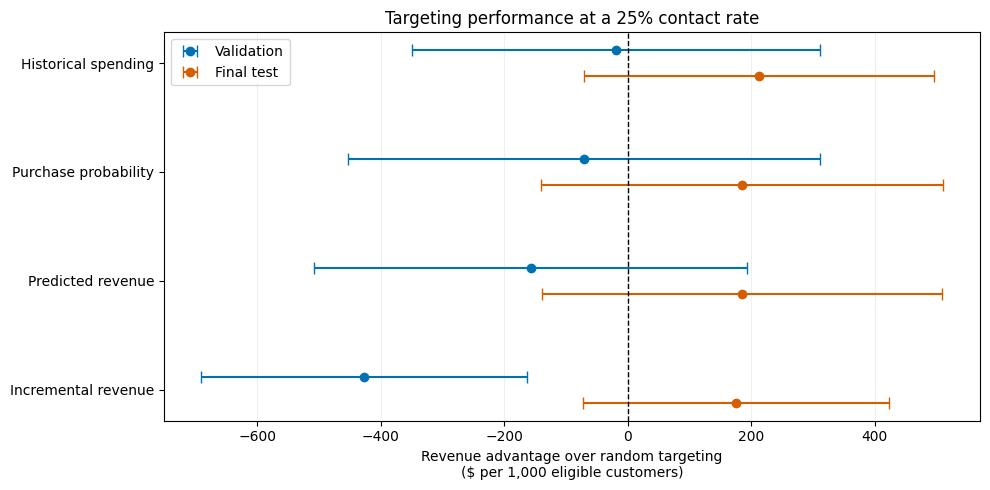

In [36]:
import matplotlib.pyplot as plt

rule_order = [
    "Historical spending",
    "Purchase probability",
    "Predicted revenue",
    "Incremental revenue"
]

validation_plot = validation_comparison.reindex(rule_order)
test_plot = test_budget_comparison.xs(
    "25%", level="Contact rate"
).reindex(rule_order)

y_positions = np.arange(len(rule_order))
fig, ax = plt.subplots(figsize=(10, 5))

for table, offset, color, label in [
    (validation_plot, -0.12, "#0072B2", "Validation"),
    (test_plot, 0.12, "#D55E00", "Final test")
]:
    estimates = table["Advantage over random"]

    errors = np.vstack([
        estimates - table["95% CI lower"],
        table["95% CI upper"] - estimates
    ])

    ax.errorbar(
        estimates,
        y_positions + offset,
        xerr=errors,
        fmt="o",
        color=color,
        capsize=4,
        label=label
    )

ax.axvline(0, color="black", linestyle="--", linewidth=1)
ax.set_yticks(y_positions)
ax.set_yticklabels(rule_order)
ax.invert_yaxis()

ax.set_title("Targeting performance at a 25% contact rate")
ax.set_xlabel(
    "Revenue advantage over random targeting\n"
    "($ per 1,000 eligible customers)"
)

ax.grid(axis="x", alpha=0.2)
ax.legend()
fig.tight_layout()

fig.savefig(
    "targeting_comparison_25pct.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [37]:
from pathlib import Path
import shutil
from google.colab import files

results_dir = Path("targeting_project_results")
results_dir.mkdir(exist_ok=True)

budget_comparison.reset_index().to_csv(
    results_dir / "validation_comparisons.csv",
    index=False
)

test_budget_comparison.reset_index().to_csv(
    results_dir / "final_test_comparisons.csv",
    index=False
)

primary_test_summary = pd.DataFrame([{
    "contact_rate": test_contact_rate,
    "selected_customers": test_n_to_contact,
    "advantage_per_1000": primary_estimate_test,
    "approximate_ci_lower": primary_lower_test,
    "approximate_ci_upper": primary_upper_test,
    "bootstrap_ci_lower": bootstrap_lower_test,
    "bootstrap_ci_upper": bootstrap_upper_test
}])

primary_test_summary.to_csv(
    results_dir / "primary_test_summary.csv",
    index=False
)

shutil.copy2(
    "targeting_comparison_25pct.png",
    results_dir / "targeting_comparison_25pct.png"
)

archive_path = shutil.make_archive(
    "targeting_project_results",
    "zip",
    root_dir=results_dir
)

files.download(archive_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [38]:
import platform
from importlib.metadata import version
from pathlib import Path
from google.colab import files

packages = ["numpy", "pandas", "scipy", "scikit-learn", "matplotlib"]

requirements_text = "\n".join(
    f"{package}=={version(package)}"
    for package in packages
) + "\n"

Path("requirements.txt").write_text(
    requirements_text, encoding="utf-8"
)

print("Python version:", platform.python_version())
print(requirements_text)

files.download("requirements.txt")

Python version: 3.13.16
numpy==2.1.3
pandas==2.2.3
scipy==1.16.3
scikit-learn==1.6.1
matplotlib==3.10.0



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [39]:
import hashlib
from pathlib import Path

dataset_sha256 = hashlib.sha256(
    Path(file_name).read_bytes()
).hexdigest()

print("Uploaded filename:", file_name)
print("SHA-256:", dataset_sha256)

Uploaded filename: hillstrom (2).csv
SHA-256: 0e5893329d8b93cefecc571777672028290ab69865718020c78c7284f291aece


## Exploratory extension: Does incremental targeting add value beyond simpler rules?

**Timing and scope.** This extension was specified after examining the original validation and final test results. It is exploratory and supplements the original analysis.

**Research question.** At a fixed 25% contact rate, does incremental-revenue targeting generate more revenue than targeting by historical spending or predicted revenue under email?

**Fixed design.** Retain the existing training, validation, and test samples, seven baseline predictors, fitted models, and targeting scores. Each rule will select the same 2,130 test customers as in the original analysis. No models or contact rates will be selected using these additional results.

**Direct comparisons.**
1. Incremental-revenue targeting minus historical-spending targeting.
2. Incremental-revenue targeting minus predicted-revenue targeting.

Report revenue differences per 1,000 eligible customers, using paired comparisons because the rules are evaluated on the same customers.

**Evaluation methods.** Calculate both the original inverse-probability estimates and augmented inverse-probability estimates. The augmented estimator will combine the known treatment-assignment probability with predictions from the existing email and control revenue models, fitted using training observations only.

**Uncertainty.** Report paired approximate 95% confidence intervals and treatment-stratified bootstrap intervals, holding fitted models and selection labels fixed. Intervals are pointwise and do not account for the full model-fitting process or multiple comparisons.

**Customer profiles.** Describe baseline characteristics of customers selected by incremental targeting but excluded by historical-spending targeting, and vice versa. These descriptive comparisons will not be interpreted as causal explanations.

**Interpretation.** Report all specified comparisons regardless of direction or statistical significance. Assess whether conclusions differ across evaluation methods, without treating agreement as independent replication or inconclusive estimates as evidence of equivalence.

In [40]:
# Reconstruct the fixed 25% targeting rules.
extension_policies_test = pd.DataFrame(index=test_df.index)

for rule in [
    "Historical spending",
    "Predicted revenue",
    "Incremental revenue"
]:
    selected = scores_test[rule].nlargest(
        test_n_to_contact, keep="first"
    ).index

    extension_policies_test[rule] = (
        extension_policies_test.index.isin(selected)
    )

# Paired revenue differences, in dollars per 1,000 eligible customers.
extension_ipw_differences = pd.DataFrame({
    f"Incremental minus {benchmark.lower()}": (
        extension_policies_test["Incremental revenue"].astype(float)
        - extension_policies_test[benchmark].astype(float)
    ) * ipw_score_test * 1000
    for benchmark in ["Historical spending", "Predicted revenue"]
})

extension_estimates = extension_ipw_differences.mean()
extension_se = (
    extension_ipw_differences.std(ddof=1)
    / len(test_df) ** 0.5
)
extension_z = stats.norm.ppf(0.975)

extension_ipw_comparison = pd.DataFrame({
    "Revenue difference per 1,000": extension_estimates,
    "95% CI lower": extension_estimates - extension_z * extension_se,
    "95% CI upper": extension_estimates + extension_z * extension_se
})

extension_ipw_comparison.round(2)

,"Revenue difference per 1,000",95% CI lower,95% CI upper
Incremental minus historical spending,-37.35,-328.47,253.76
Incremental minus predicted revenue,-9.05,-317.42,299.31


In [41]:
# Spending predictions from the existing training-only models.
extension_mu_email = pd.Series(
    revenue_model.predict(test_df[feature_columns]),
    index=test_df.index
)
extension_mu_control = pd.Series(
    control_revenue_model.predict(test_df[feature_columns]),
    index=test_df.index
)

# Augmented inverse-probability score for incremental revenue.
extension_treatment = test_df["treatment"]
extension_outcome = test_df["spend"]

extension_aipw_score = (
    extension_mu_email - extension_mu_control
    + extension_treatment
      * (extension_outcome - extension_mu_email) / p_email
    - (1 - extension_treatment)
      * (extension_outcome - extension_mu_control) / (1 - p_email)
)

# Evaluate exactly the same fixed targeting rules.
extension_aipw_differences = pd.DataFrame({
    f"Incremental minus {benchmark.lower()}": (
        extension_policies_test["Incremental revenue"].astype(float)
        - extension_policies_test[benchmark].astype(float)
    ) * extension_aipw_score * 1000
    for benchmark in ["Historical spending", "Predicted revenue"]
})

extension_aipw_estimates = extension_aipw_differences.mean()
extension_aipw_se = (
    extension_aipw_differences.std(ddof=1)
    / len(test_df) ** 0.5
)

extension_aipw_comparison = pd.DataFrame({
    "Revenue difference per 1,000": extension_aipw_estimates,
    "95% CI lower": (
        extension_aipw_estimates - extension_z * extension_aipw_se
    ),
    "95% CI upper": (
        extension_aipw_estimates + extension_z * extension_aipw_se
    )
})

extension_aipw_comparison.round(2)

,"Revenue difference per 1,000",95% CI lower,95% CI upper
Incremental minus historical spending,-52.69,-342.26,236.88
Incremental minus predicted revenue,-7.41,-314.27,299.45


In [42]:
# Combine the two comparisons under both evaluation methods.
extension_all_differences = pd.concat(
    {
        "IPW": extension_ipw_differences,
        "AIPW": extension_aipw_differences
    },
    axis=1,
    names=["Estimator", "Comparison"]
)

extension_values = extension_all_differences.to_numpy()
extension_email_mask = (
    test_df.loc[extension_all_differences.index, "treatment"]
    .to_numpy() == 1
)

extension_email_values = extension_values[extension_email_mask]
extension_control_values = extension_values[~extension_email_mask]

extension_rng = np.random.default_rng(2026)
extension_bootstrap = np.empty((5000, extension_values.shape[1]))

for b in range(5000):
    email_draw = extension_rng.integers(
        0, len(extension_email_values),
        size=len(extension_email_values)
    )
    control_draw = extension_rng.integers(
        0, len(extension_control_values),
        size=len(extension_control_values)
    )

    extension_bootstrap[b] = (
        extension_email_values[email_draw].sum(axis=0)
        + extension_control_values[control_draw].sum(axis=0)
    ) / len(test_df)

extension_bootstrap_summary = pd.DataFrame(
    {
        "Revenue difference per 1,000":
            extension_all_differences.mean().to_numpy(),
        "Bootstrap 95% CI lower":
            np.quantile(extension_bootstrap, 0.025, axis=0),
        "Bootstrap 95% CI upper":
            np.quantile(extension_bootstrap, 0.975, axis=0)
    },
    index=extension_all_differences.columns
)

extension_bootstrap_summary.round(2)

Revenue difference per 1,000  \
Estimator Comparison                                                            
IPW       Incremental minus historical spending                        -37.35   
          Incremental minus predicted revenue                           -9.05   
AIPW      Incremental minus historical spending                        -52.69   
          Incremental minus predicted revenue                           -7.41   

                                                 Bootstrap 95% CI lower  \
Estimator Comparison                                                      
IPW       Incremental minus historical spending                 -321.24   
          Incremental minus predicted revenue                   -318.21   
AIPW      Incremental minus historical spending                 -338.91   
          Incremental minus predicted revenue                   -315.70   

                                                 Bootstrap 95% CI upper  
Estimator Comparison                                                     
IPW       Incremental minus historical spending                  252.92  
          Incremental minus predicted revenue                    287.84  
AIPW      Incremental minus historical spending                  236.51  
          Incremental minus predicted revenue                    289.97

In [43]:
extension_inc = extension_policies_test["Incremental revenue"]
extension_hist = extension_policies_test["Historical spending"]

extension_profile_groups = {
    "Both rules": extension_inc & extension_hist,
    "Incremental only": extension_inc & ~extension_hist,
    "Historical spending only": ~extension_inc & extension_hist,
    "Neither rule": ~extension_inc & ~extension_hist
}

extension_profile_rows = []

for group_name, selected_mask in extension_profile_groups.items():
    group = test_df.loc[selected_mask]

    extension_profile_rows.append({
        "Selection group": group_name,
        "Customers": len(group),
        "Mean prior spending ($)": group["history"].mean(),
        "Median prior spending ($)": group["history"].median(),
        "Mean recency (months)": group["recency"].mean(),
        "Prior men's purchase (%)": 100 * group["mens"].mean(),
        "Prior women's purchase (%)": 100 * group["womens"].mean()
    })

extension_customer_profiles = pd.DataFrame(
    extension_profile_rows
).set_index("Selection group")

extension_customer_profiles.round(2)

,Customers,Mean prior spending ($),Median prior spending ($),Mean recency (months),Prior men's purchase (%),Prior women's purchase (%)
Selection group,,,,,,
Both rules,1288,668.24,596.81,4.34,66.85,77.33
Incremental only,842,190.01,215.36,5.87,38.48,94.54
Historical spending only,842,485.75,426.00,4.84,56.89,43.11
Neither rule,5551,116.65,97.61,6.21,54.78,45.22


## Exploratory extension findings

### Direct revenue comparisons

At the fixed 25% contact rate, incremental-revenue targeting did not demonstrate a clear advantage over either simpler targeting rule.

Using inverse-probability weighting, its estimated revenue difference was −\$37.35 relative to historical-spending targeting and −\$9.05 relative to predicted-revenue targeting, per 1,000 eligible customers.

Augmented inverse-probability estimates were similar: −\$52.69 relative to historical spending and −\$7.41 relative to predicted revenue. Their approximate 95% confidence intervals were −\$342.26 to \$236.88 and −\$314.27 to \$299.45, respectively. Adjustment produced little improvement in precision.

All corresponding stratified bootstrap intervals also included zero. These results remain inconclusive and do not establish equivalence between strategies.

### How the selected audiences differ

Historical-spending and incremental-revenue targeting each selected 2,130 test customers, sharing 1,288 selections. Each rule selected 842 customers excluded by the other, representing 39.5% of its audience.

Customers selected only by incremental targeting had lower mean prior spending (\$190.01 versus \$485.75) and a longer average time since their last purchase (5.87 versus 4.84 months) than customers selected only by historical spending. Prior women’s merchandise purchases were also more common in the incremental-only group (94.54% versus 43.11%).

These profiles describe how the fitted rules allocate contacts. They do not establish that the characteristics cause greater responsiveness or explain the model’s decisions independently of other predictors.

### Interpretation

The incremental rule substantially reallocates contacts toward a different customer audience, but the available evidence does not establish a revenue benefit from that reallocation. This distinguishes a change in targeting decisions from a demonstrated improvement in business outcomes.

This extension was developed after inspecting the original test results. Its comparisons are exploratory, and uncertainty estimates hold fitted models and selection labels fixed.


In [44]:
from pathlib import Path
import shutil
from google.colab import files

extension_results_dir = Path("targeting_extension_results")
extension_results_dir.mkdir(exist_ok=True)

extension_ipw_comparison.rename_axis("Comparison").reset_index().to_csv(
    extension_results_dir / "direct_comparisons_ipw.csv",
    index=False
)

extension_aipw_comparison.rename_axis("Comparison").reset_index().to_csv(
    extension_results_dir / "direct_comparisons_aipw.csv",
    index=False
)

extension_bootstrap_summary.reset_index().to_csv(
    extension_results_dir / "direct_comparisons_bootstrap.csv",
    index=False
)

extension_customer_profiles.reset_index().to_csv(
    extension_results_dir / "customer_selection_profiles.csv",
    index=False
)

extension_notes = """Exploratory targeting extension

Specified after inspecting the original test results.
Contact rate: nominal 25%; 2,130 of 8,523 test customers selected per rule.
Models and targeting selections remain fixed.

Revenue comparisons are dollars per 1,000 eligible customers.
Negative differences favor the comparison rule.
IPW and AIPW tables contain approximate pointwise 95% intervals.
Bootstrap table contains pointwise percentile intervals from 5,000
resamples within treatment groups, using random seed 2026.
Intervals do not capture the full model-fitting process.

Customer profiles describe pre-campaign characteristics.
Merchandise purchase indicators do not identify customer gender.
CSV files retain unrounded values.
"""

(extension_results_dir / "README.txt").write_text(
    extension_notes, encoding="utf-8"
)

extension_archive = shutil.make_archive(
    "targeting_extension_results",
    "zip",
    root_dir=extension_results_dir
)

files.download(extension_archive)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>